# Start

In [1]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import os
from skimage.filters import frangi

In [2]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"
path_crop_out = path_processed / "od_images"

size_preview = (500, 500)

seed = 123

In [3]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT,Height,Width
str,i64,str,f64,str,i64,i64
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN""",1918,1918
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN""",1929,1929
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN""",1940,1940
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN""",1893,1893
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN""",1900,1900


# Tools

In [4]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [5]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [6]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [7]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [8]:
def mark(img, max_loc, crop_ratio=0.3):
    out = img.copy()
    h, w = out.shape[:2]

    crop_w = int(w * crop_ratio)
    crop_h = int(h * crop_ratio)

    x1 = max(max_loc[0] - crop_w // 2, 0)
    y1 = max(max_loc[1] - crop_h // 2, 0)
    x2 = min(max_loc[0] + crop_w // 2, w)
    y2 = min(max_loc[1] + crop_h // 2, h)

    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 10)
    cv2.drawMarker(out, max_loc, (0, 0, 255), cv2.MARKER_CROSS, 100, 15)

    return out

In [78]:
def shade_fov_region(img, mask, alpha=0.4, color=(0, 255, 0)):
    """
    Shades the 'ignored' regions of an image based on a binary mask.

    Args:
        img: Original BGR image.
        mask: Binary mask (uint8, same size as img). 255 = keep, 0 = shade.
        alpha: Transparency of the shade (0.0 to 1.0).
        color: BGR color for the shade
    """
    overlay = img.copy()

    if len(mask.shape) == 3:
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
    overlay[mask == 0] = color
    output = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

    return output

# OD - Texture

In [ ]:
# Params
crop_ratio = 0.3
crop_resize = 512

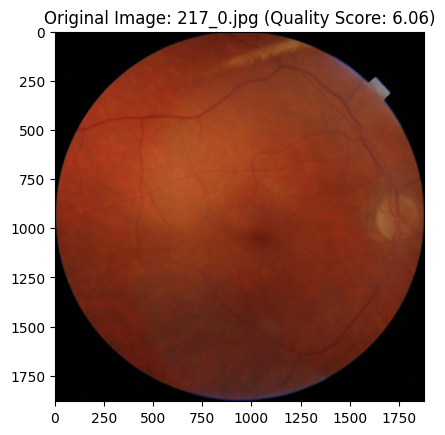

In [296]:
# img_file_name = "273_0"  # od near fov
# img_file_name = "261_1"  # od near fov + genrally bright
# img_file_name = "188_1"  # od near fov
# img_file_name = "31_2"  # random white spot + halo
img_file_name = "217_0" # 2 bright spot
# img_file_name = None

# generate random sample + extract metadata
sample_df = (
    df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
    if img_file_name is None
    else df.filter(pl.col("Image Name") == img_file_name + ".jpg")
)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name
sample_height = sample_df.select("Height").item()
sample_width = sample_df.select("Width").item()

# load and preview
img_ori = cv2.imread(sample_path)
plt.title(f"Original Image: {sample_img_name} (Quality Score: {sample_quality})")
plt.imshow(cv2.cvtColor(img_ori, cv2.COLOR_BGR2RGB))

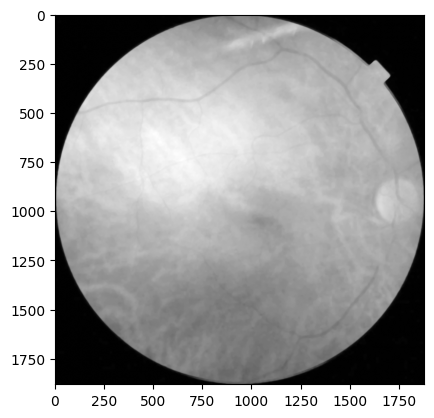

In [297]:
hsv = cv2.cvtColor(img_ori, cv2.COLOR_BGR2HSV)
v_channel = hsv[:, :, 2]
v_smooth = cv2.medianBlur(v_channel, 11)

plt.imshow(v_smooth, cmap="gray")

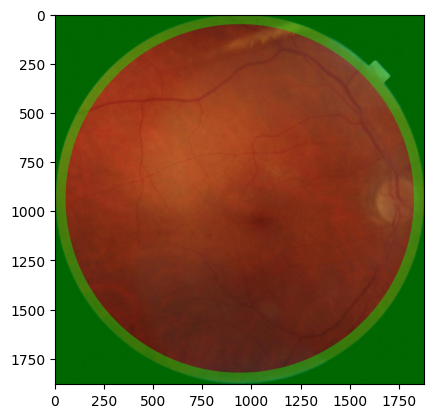

In [298]:
# get fov mask
def get_fov_mask(img_input):
    gray = img_input[:, :, 1]  # Green channel (cleanest boundary)
    blurred = cv2.medianBlur(gray, 31)
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=1000,  # Assume only ONE big circle exists
        param1=50,
        param2=30,
        minRadius=int(img_input.shape[0] * 0.3),  # At least 30% of image height
        maxRadius=int(img_input.shape[0] * 0.6),
    )
    mask = np.zeros_like(gray)
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0, :]:
            center = (i[0], i[1])  # x, y
            radius = i[2]
            # Draw the detected circle into a binary mask
            mask = cv2.circle(mask, center, radius, 255, -1)

    # erode fov mask
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (101, 101))
    mask_eroded = cv2.erode(mask, kernel, iterations=1)

    return mask_eroded


plt.imshow(
    cv2.cvtColor(shade_fov_region(img_ori, get_fov_mask(img_ori)), cv2.COLOR_BGR2RGB)
)

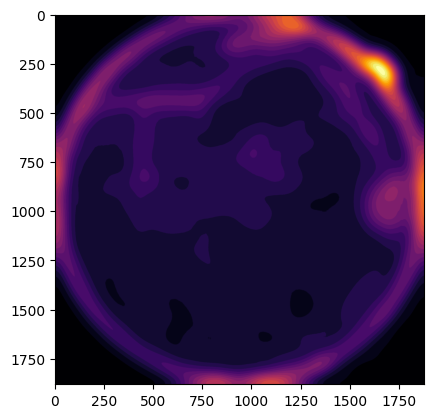

In [299]:
def get_texture_map(img_bgr):
    red = img_bgr[:, :, 1]
    red = cv2.medianBlur(red, 15)  # Remove speckle noise

    # Structural Gradient (Dilation - Erosion)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    grad = cv2.morphologyEx(red, cv2.MORPH_GRADIENT, kernel)

    # Create a "Hotspot" of density
    blur_size = int(img_bgr.shape[1] * 0.15)  # 15% of width
    if blur_size % 2 == 0:
        blur_size += 1
    texture_density = cv2.GaussianBlur(grad, (blur_size, blur_size), 0)

    return cv2.normalize(texture_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)


texture_map = get_texture_map(img_ori)
plt.imshow(texture_map, cmap="inferno")

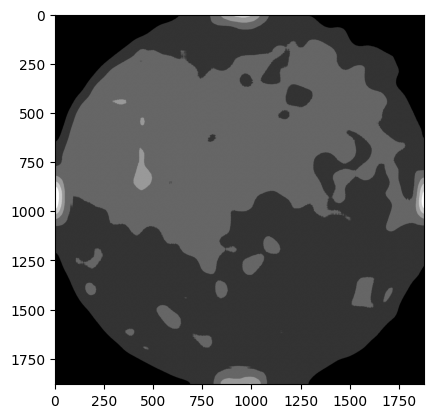

In [300]:
def get_vessel_map(img):
    green = img[:, :, 1]
    vessels = cv2.morphologyEx(
        green,
        cv2.MORPH_BLACKHAT,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
    )
    vessel_density = cv2.GaussianBlur(vessels, (201, 201), 0)
    vessel_map = cv2.normalize(
        vessel_density, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F
    )
    return vessel_map

vessel_map = get_vessel_map(img_ori)
plt.imshow(vessel_map, cmap="grey")

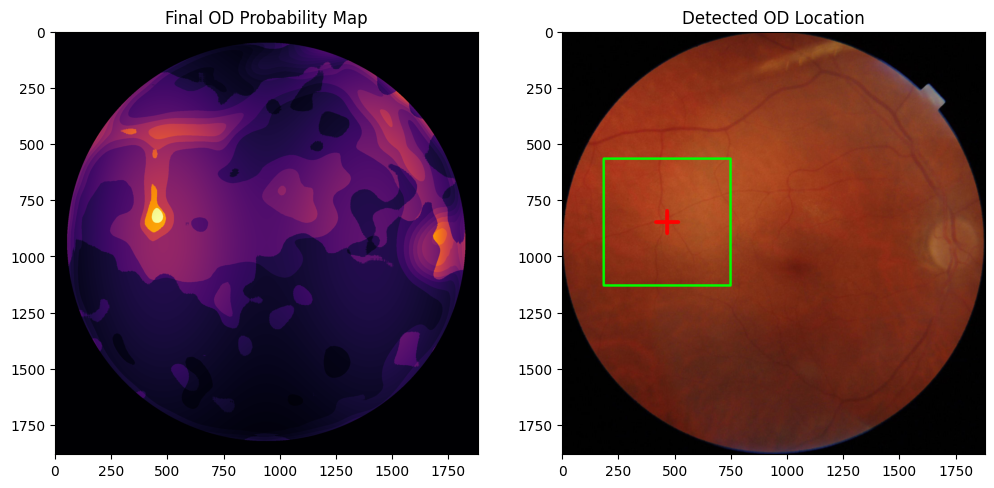

In [301]:
def find_od(img_bgr, fov_mask, map_ls):
    # GENERATE SPATIAL PENALTY
    h, w = img_bgr.shape[:2]
    x = np.linspace(0, w, w)
    y = np.linspace(0, h, h)
    X, Y = np.meshgrid(x, y)
    mu_y = h / 2
    sigma_x = w / 6  # Horizontal spread
    sigma_y = h / 3  # Vertical spread
    penalty_left = np.exp(
        -((X - w * 0.25) ** 2 / (2 * sigma_x**2) + (Y - mu_y) ** 2 / (2 * sigma_y**2))
    )
    penalty_right = np.exp(
        -((X - w * 0.75) ** 2 / (2 * sigma_x**2) + (Y - mu_y) ** 2 / (2 * sigma_y**2))
    )
    spatial_penalty = penalty_left + penalty_right
    spatial_penalty = cv2.normalize(spatial_penalty, None, 0, 1, cv2.NORM_MINMAX)

    # FIND OVERLAPPING MAP
    combined_prob = spatial_penalty
    for map in map_ls:
        combined_prob *= map

    # APPLY FOV MASK
    mask_f = fov_mask.astype(np.float32) / 255.0
    final_map = combined_prob * mask_f

    # LOCATE THE PEAK
    final_map_8u = cv2.normalize(final_map, None, 0, 255, cv2.NORM_MINMAX).astype(
        np.uint8
    )
    _, _, _, max_loc = cv2.minMaxLoc(final_map_8u)

    return max_loc, final_map_8u


fov_mask = get_fov_mask(img_ori)
max_loc, final_map = find_od(
    img_ori,
    fov_mask,
    map_ls=[
        texture_map,
        vessel_map,
    ],
)

# Visualize the final OD probability map and the detected location
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Final OD Probability Map")
plt.imshow(final_map, cmap="inferno")
plt.subplot(1, 2, 2)
img_marked = mark(img_ori, max_loc)
plt.title("Detected OD Location")
plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))

# OD Batch crop

In [436]:
def crop_od(img, max_loc, crop_ratio=0.3):
    img_ori = img.copy()

    crop_resize = 512
    sample_height = img_ori.shape[0]
    sample_width = img_ori.shape[1]

    # cropping
    crop_width = int(sample_width * crop_ratio)
    crop_height = int(sample_height * crop_ratio)
    
    x1 = max(max_loc[0] - crop_width // 2, 0)
    y1 = max(max_loc[1] - crop_height // 2, 0)
    x2 = min(max_loc[0] + crop_width // 2, sample_width)
    y2 = min(max_loc[1] + crop_height // 2, sample_height)

    cropped_img = img_ori[y1:y2, x1:x2]
    cropped_resize_img = cv2.resize(cropped_img, (crop_resize, crop_resize))

    return cropped_resize_img

In [437]:
def od_bright(img):
    img_ori = img.copy()

    kernel_clean_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (15, 15)
    )  # remove random pixel
    kernel_erode_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (51, 51)
    )  # erode fov region to avoid halo
    erode_iter = 10
    fov_thres_val = 20
    gaussian_blur_kernel: tuple = (71, 71)

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

    # find brightest spot
    img_red = img_ori[:, :, 2]
    img_blur = cv2.GaussianBlur(img_red, gaussian_blur_kernel, 0)
    masked_img = cv2.bitwise_and(img_blur, img_blur, mask=fov_mask)
    _, _, _, max_loc = cv2.minMaxLoc(masked_img)
    return max_loc

In [438]:
def od_sobel(img):
    img_ori = img.copy()

    kernel_clean_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (15, 15)
    )  # remove random pixel
    kernel_erode_fov_mask = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (51, 51)
    )  # erode fov region to avoid halo
    erode_iter = 10
    fov_thres_val = 20

    sobel_ksize = 7
    gaussian_blur_kernel: tuple = (51, 51)

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)

    # sobel detection
    gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    grad = cv2.magnitude(
        cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=sobel_ksize),
        cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=sobel_ksize),
    )
    grad_blur = cv2.GaussianBlur(np.abs(grad), gaussian_blur_kernel, 0)
    _, _, _, loc_texture = cv2.minMaxLoc(
        cv2.bitwise_and(np.abs(grad_blur), np.abs(grad_blur), mask=fov_mask)
    )
    return loc_texture

In [439]:
def od_vessel(img):
    img_ori = img.copy()
    kernel_erode_fov_mask = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (101, 101))
    erode_iter = 1
    fov_thres_val = 20

    gaussian_blur_kernel: tuple = (51, 51)
    green = img_ori[:, :, 1]

    vessels = frangi(
        green,
        sigmas=range(2, 30, 4),
        alpha=0.7,
        beta=0.5,
        gamma=0.05,
        black_ridges=True,
    )

    # get fov mask
    img_gray = cv2.cvtColor(img_ori, cv2.COLOR_BGR2GRAY)
    _, fov_mask = cv2.threshold(img_gray, fov_thres_val, 255, cv2.THRESH_BINARY)

    # clean fov mask
    fov_mask = cv2.morphologyEx(fov_mask, cv2.MORPH_ERODE, kernel_clean_fov_mask)
    fov_mask = cv2.erode(fov_mask, kernel_erode_fov_mask, iterations=erode_iter)
    vessels_img = cv2.normalize(vessels, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    vessel_density = cv2.GaussianBlur(vessels_img, gaussian_blur_kernel, 0)
    masked_vessels = cv2.bitwise_and(vessel_density, vessel_density, mask=fov_mask)
    _, _, _, loc_vessels = cv2.minMaxLoc(masked_vessels)

    return loc_vessels

In [440]:
import random

img_ls = df.select("Image Name").to_numpy().flatten().tolist()
i = random.sample(img_ls, 1)[0]
img_path = path_raw_img / i

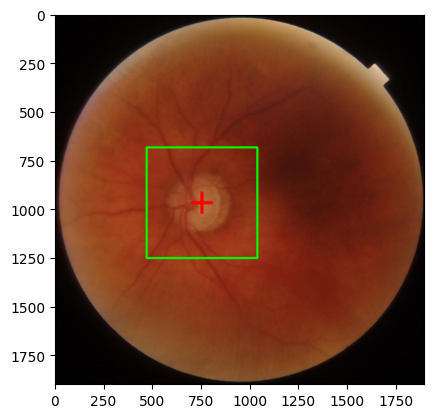

In [441]:
_maxloc = od_bright(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)

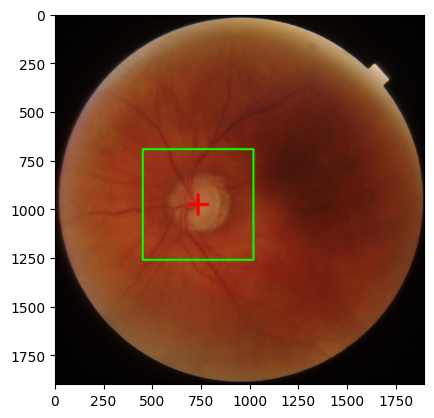

In [442]:
_maxloc = od_sobel(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)

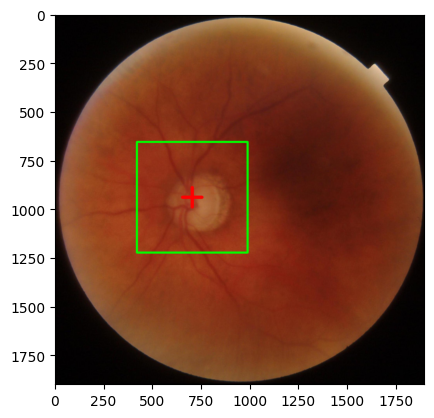

In [443]:
_maxloc = od_vessel(cv2.imread(img_path))
cropped_img = crop_od(cv2.imread(img_path), _maxloc)
plt.imshow(
    cv2.cvtColor(
        mark(cv2.imread(img_path), max_loc=_maxloc, crop_ratio=0.3), cv2.COLOR_BGR2RGB
    )
)

In [ ]:
# params
path_raw_img = here() / "data" / "raw" / "Images"
path_processed = here() / "data" / "processed"
path_crop_bright = here() / "data" / "processed" / "od_bright"
path_crop_sobel = here() / "data" / "processed" / "od_sobel"
path_crop_vessel = here() / "data" / "processed" / "od_vessel"

df = pl.read_csv(path_processed / "labels.csv")
img_ls = df.select("Image Name").to_numpy().flatten().tolist()
try:
    os.mkdir(path_crop_bright)
except FileExistsError:
    pass
try:
    os.mkdir(path_crop_sobel)
except FileExistsError:
    pass
try:
    os.mkdir(path_crop_vessel)
except FileExistsError:
    pass


loc_bright_ls = []
loc_sobel_ls = []
loc_vessel_ls = []

for i in img_ls:
    current_img_path = path_raw_img / i
    current_img = cv2.imread(current_img_path)

    # find OD loc
    loc_bright = od_bright(current_img)
    loc_sobel = od_sobel(current_img)
    loc_vessel = od_vessel(current_img)

    # crop
    cropped_bright = crop_od(current_img, loc_bright)
    cropped_sobel = crop_od(current_img, loc_sobel)
    cropped_vessel = crop_od(current_img, loc_vessel)

    # save
    cv2.imwrite(str(path_crop_bright / i), cropped_bright)
    cv2.imwrite(str(path_crop_sobel / i), cropped_sobel)
    cv2.imwrite(str(path_crop_vessel / i), cropped_vessel)

    # append to list for df
    loc_bright_ls.append(str(loc_bright))
    loc_sobel_ls.append(str(loc_sobel))
    loc_vessel_ls.append(str(loc_vessel))

df = df.with_columns(
    pl.Series("OD_loc_bright", loc_bright_ls),
    pl.Series("OD_loc_sobel", loc_sobel_ls),
    pl.Series("OD_loc_vessel", loc_vessel_ls),
)

df.write_csv(path_processed / "labels_od.csv")